# 120 Years of Olympic History: Trends Analysis

## About the Dataset
This dataset (`athlete_events.csv`) contains **271,116 records** of individual athlete participation across every Olympic Games from **1896 to 2016** (both Summer and Winter), sourced from historical Olympic records.

Each row represents one athlete's participation in one event, with the following key fields:
- **Demographics:** `Name`, `Sex`, `Age`, `Height`, `Weight`, `Team`, `NOC` (country code)
- **Event details:** `Games`, `Year`, `Season`, `City`, `Sport`, `Event`
- **Outcome:** `Medal` (Gold / Silver / Bronze / not awarded)

## Purpose of This Analysis
This project explores broad historical trends across the full 120-year span of the Olympics, using Python (Pandas, NumPy, Matplotlib) for cleaning, feature engineering, and visualization. Specifically, it looks at:
- How medal success is distributed across gender, age, and physical build (BMI)
- Which countries and sports have historically produced the most medals
- How participation (overall and by gender) has grown and shifted over time
- How the average physical profile of athletes has changed decade by decade

The goal is not just to report numbers, but to practice deriving new features (via NumPy) from raw data and to draw honest, appropriately-caveated conclusions from a large real-world dataset.


## Setup & Data Loading


In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sn 

import warnings 
warnings.filterwarnings("ignore")

In [2]:
df_olympic = pd.read_csv("athlete_events.csv")

In [3]:
df_olympic.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [4]:
df_olympic.shape

(271116, 15)

In [5]:
df_olympic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  object 
 2   Sex     271116 non-null  object 
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  object 
 7   NOC     271116 non-null  object 
 8   Games   271116 non-null  object 
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  object 
 11  City    271116 non-null  object 
 12  Sport   271116 non-null  object 
 13  Event   271116 non-null  object 
 14  Medal   39783 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 31.0+ MB


In [6]:
df_olympic.describe()

,ID,Age,Height,Weight,Year
count,271116.000000,261642.000000,210945.000000,208241.000000,271116.000000
mean,68248.954396,25.556898,175.338970,70.702393,1978.378480
std,39022.286345,6.393561,10.518462,14.348020,29.877632
min,1.000000,10.000000,127.000000,25.000000,1896.000000
25%,34643.000000,21.000000,168.000000,60.000000,1960.000000
50%,68205.000000,24.000000,175.000000,70.000000,1988.000000
75%,102097.250000,28.000000,183.000000,79.000000,2002.000000
max,135571.000000,97.000000,226.000000,214.000000,2016.000000


In [7]:
df_olympic.isnull().sum()

ID             0
Name           0
Sex            0
Age         9474
Height     60171
Weight     62875
Team           0
NOC            0
Games          0
Year           0
Season         0
City           0
Sport          0
Event          0
Medal     231333
dtype: int64

### Initial Observations
- The dataset has **271,116 rows** and **15 columns**, spanning 1896–2016.
- `Age`, `Height`, and `Weight` have a meaningful number of missing values (9,474 / 60,171 / 62,875 respectively) — likely due to incomplete historical record-keeping, especially for earlier Games.
- `Medal` is missing for the vast majority of rows (~231K), but as explored below, this is expected rather than a data quality issue.


### Handling Missing Medal Values
- `Medal` is null for ~85% of records, but this is not a data quality issue — it reflects that most Olympic 
  participants do not win a medal (only top 3 finishers per event do).
- Rather than dropping the column or treating this as missing data, nulls were filled with `'No Medal'`, 
  turning this into a clean categorical column and preserving the ability to analyze medal counts and win rates.

In [8]:
df_olympic['Medal'] = df_olympic['Medal'].fillna('No Medal')

In [9]:
df_olympic.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,No Medal
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,No Medal
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,No Medal
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,No Medal


### Feature: `Won_Medal`
A binary flag created with `np.where()` — `1` if the athlete won any medal (Gold/Silver/Bronze), `0` if not. This makes later aggregation (win rates by group) much simpler than working with the 4-category text column directly.


In [10]:
df_olympic['Won_Medal'] = np.where(df_olympic['Medal'] == 'No Medal', 0, 1)

In [11]:
df_olympic.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,Won_Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,No Medal,0
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,No Medal,0
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,No Medal,0
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,1
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,No Medal,0


## Overall Medal Win Rate


In [12]:
print(df_olympic['Won_Medal'].mean())  # overall medal-win rate

0.14673792767671404


**Insight:** across all 271,116 athlete-event records, the overall medal win rate is **14.67%** — meaning roughly 1 in 7 recorded participations resulted in a medal.


## Medal Win Rate by Gender


In [13]:
df_olympic.groupby('Sex')['Won_Medal'].mean()  # win rate by gender

Sex
F    0.151002
M    0.145121
Name: Won_Medal, dtype: float64

**Insight:** win rate is nearly identical between genders — **15.1% for women vs. 14.5% for men** — a small but real difference. This is likely influenced by historically smaller, more competitive fields in women's events during earlier decades (fewer entrants per medal available), rather than a meaningful performance gap.


##  Medal Win Rate by Age Group

Grouping by raw single-year `Age` produces noisy, misleading results at the extremes — for example, a single 10-year-old athlete who happened to medal would show as a "100% win rate" for that age, which isn't a meaningful pattern. Instead, ages are bucketed into groups using `np.select()`, so each group has enough athletes for the win rate to be statistically meaningful.


In [14]:
conditions = [
    df_olympic['Age'] < 20,
    df_olympic['Age'].between(20, 29),
    df_olympic['Age'].between(30, 39),
    df_olympic['Age'] >= 40
]
choices = ['Under 20', '20-29', '30-39', '40+']

df_olympic['Age_Group'] = np.select(conditions, choices, default='Unknown')


In [15]:
df_olympic.groupby('Age_Group')['Won_Medal'].mean()


Age_Group
20-29       0.154970
30-39       0.160950
40+         0.137807
Under 20    0.105501
Unknown     0.077264
Name: Won_Medal, dtype: float64

**Insight:** the **30-39** age group actually has the highest win rate (**16.1%**), narrowly ahead of **20-29** (**15.5%**) — both meaningfully higher than **Under 20** (**10.6%**) and **40+** (**13.8%**). This suggests peak Olympic performance skews slightly older than the popular assumption that athletes peak in their early-to-mid 20s, likely reflecting the added experience/technique advantage in many sports outweighing any decline in raw physical peak. The **'Unknown'** category (7.7%) corresponds to records with missing `Age` data, and its lower win rate is expected — bucketing removed the earlier small-sample distortion (e.g. the misleading 100% rate at age 10) seen in the raw per-age version.


## Top 5 Countries by Total Medals


In [16]:
df_olympic[df_olympic['Won_Medal'] == 1].groupby('NOC')['Medal'].count().sort_values(ascending=False).head(5)

NOC
USA    5637
URS    2503
GER    2165
GBR    2068
FRA    1777
Name: Medal, dtype: int64

**Insight:** the **USA leads by a wide margin (5,637 medals)**, followed by the **Soviet Union/URS (2,503)**, **Germany (2,165)**, **Great Britain (2,068)**, and **France (1,777)**. Note `URS` reflects the historical Soviet Union rather than modern Russia, a reminder that `NOC` codes can represent countries that no longer exist in their original form — worth keeping in mind when comparing historical vs. modern national performance.


## Participation Growth Over Time
A quick look at the first few Games shows participation grew substantially even in the early decades of the modern Olympics (from 176 athletes in 1896 to over 3,500 by the 1920s).


In [17]:
df_olympic.groupby('Year')['ID'].nunique().head(10)

Year
1896     176
1900    1224
1904     650
1906     841
1908    2024
1912    2409
1920    2676
1924    3565
1928    3703
1932    2174
Name: ID, dtype: int64

## Gender Participation Over Time
Breaking participation down by gender reveals a much more dramatic story than the raw total — shown below as a line chart, since the trend across 30+ Games is far easier to read visually than as a table.


In [18]:
df_olympic.groupby(['Year', 'Sex'])['ID'].nunique().unstack()

Sex,F,M
Year,,
1896,NaN,176.0
1900,23.0,1201.0
1904,6.0,644.0
1906,6.0,835.0
1908,44.0,1980.0
1912,53.0,2356.0
1920,78.0,2598.0
1924,169.0,3396.0
1928,340.0,3363.0


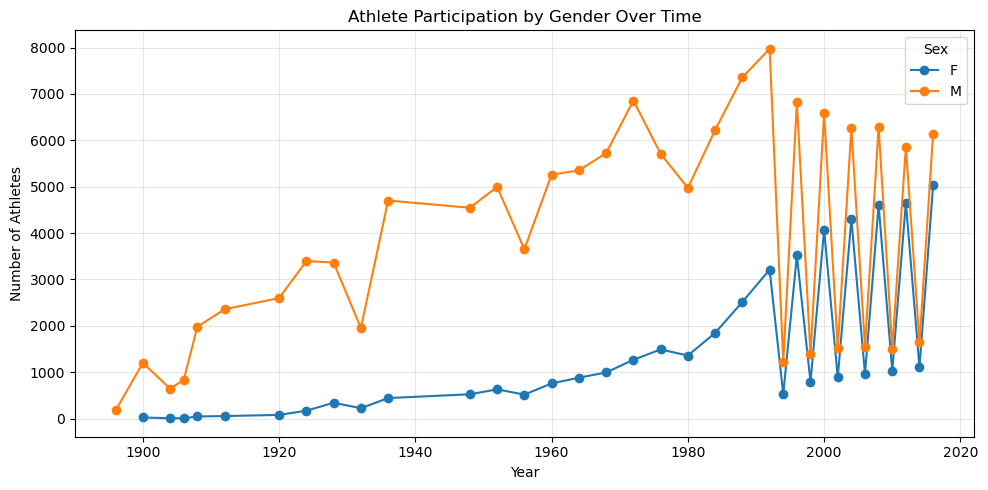

In [19]:
gender_participation = df_olympic.groupby(['Year', 'Sex'])['ID'].nunique().unstack()

gender_participation.plot(kind='line', figsize=(10,5), marker='o')
plt.title('Athlete Participation by Gender Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Athletes')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Insight:** women's participation was **essentially zero in the earliest Games (23 athletes in 1900, none recorded in 1896)** and grew dramatically over the 20th century, closing much of the gap with men's participation by the most recent Games in the dataset. This reflects the broader, well-documented historical expansion of women's access to Olympic competition.


## Average Age, Height & Weight by Decade

In [20]:
df_olympic['Decade'] = (df_olympic['Year'] // 10) * 10
df_olympic.groupby('Decade')[['Age', 'Height', 'Weight']].mean()

,Age,Height,Weight
Decade,,,
1890,23.580645,172.739130,71.387755
1900,27.369012,177.252592,74.920678
1910,27.538620,177.447989,73.117450
1920,28.894520,175.257364,71.772219
1930,29.014736,174.965489,71.161679
1940,28.783947,176.172797,71.614248
1950,26.070041,174.007796,70.229402
1960,24.764124,173.543195,69.548792
1970,24.089992,174.725991,70.059979


## Visualizing the Decade Trends
Since this spans 12 decades, a line chart makes the trend far easier to read than the raw table.


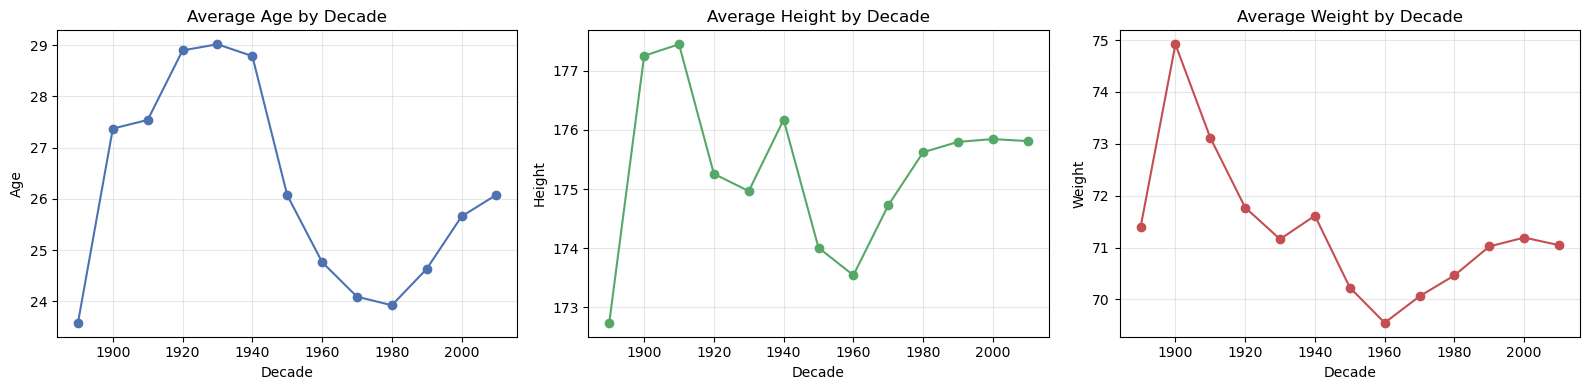

In [21]:
decade_trends = df_olympic.groupby('Decade')[['Age', 'Height', 'Weight']].mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col, color in zip(axes, ['Age', 'Height', 'Weight'], ['#4C72B0', '#55A868', '#C44E52']):
    ax.plot(decade_trends.index, decade_trends[col], marker='o', color=color)
    ax.set_title(f'Average {col} by Decade')
    ax.set_xlabel('Decade')
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Insight:** all three metrics follow a similar arc rather than a simple straight-line trend. **Age** climbs from **23.6 in the 1890s to a peak of ~29.0 in the 1930s**, then declines through the mid-century to a low of **23.9 in the 1980s**, before rising again to **~26.1 by the 2010s**. **Height** and **Weight** follow the same U-shaped pattern — rising into the early 1900s-1910s (Height peaking around 177.5cm), dipping through mid-century, then climbing again modestly into recent decades (Height ~175.8cm, Weight ~71.0kg by the 2010s).

This U-shape likely reflects the Olympics' own evolution: early Games (1890s-1910s) had a smaller, less standardized pool of competitors; the mid-century dip coincides with rapid post-WWII expansion of the Games to many more countries and sports (including ones favoring younger, leaner athletes, like gymnastics and swimming); and the recent uptick reflects the modern era's increased specialization, professionalism, and longer competitive careers.


### Feature: BMI
- `BMI` is calculated from `Height` and `Weight` using the standard formula: weight (kg) / height (m)².
- Rows with missing `Height` or `Weight` will have a null `BMI`, which is expected and handled automatically 
  by pandas during aggregation (`.mean()`, `.groupby()`, etc.).

In [22]:
df_olympic['BMI'] = df_olympic['Weight'] / ((df_olympic['Height'] / 100) ** 2)

## BMI vs. Medal Success


In [23]:
df_olympic.groupby('Won_Medal')['BMI'].mean()

Won_Medal
0    22.719604
1    23.164300
Name: BMI, dtype: float64

**Insight:** medalists have a very slightly higher average BMI (**23.16**) than non-medalists (**22.72**) — a small difference, suggesting BMI alone is not a strong predictor of medal success. This makes sense given how physically different Olympic sports are from each other (e.g., gymnastics vs. weightlifting) — BMI differences between sports likely wash out any overall pattern across the dataset as a whole.


## Medal Win Rate by Sport


In [24]:
df_olympic.groupby('Sport')['Won_Medal'].mean().sort_values(ascending=False)

Sport
Aeronautics         1.000000
Basque Pelota       1.000000
Rugby               1.000000
Cricket             1.000000
Lacrosse            1.000000
                      ...   
Gymnastics          0.084472
Biathlon            0.083384
Triathlon           0.056711
Alpine Skiing       0.048477
Art Competitions    0.043600
Name: Won_Medal, Length: 66, dtype: float64

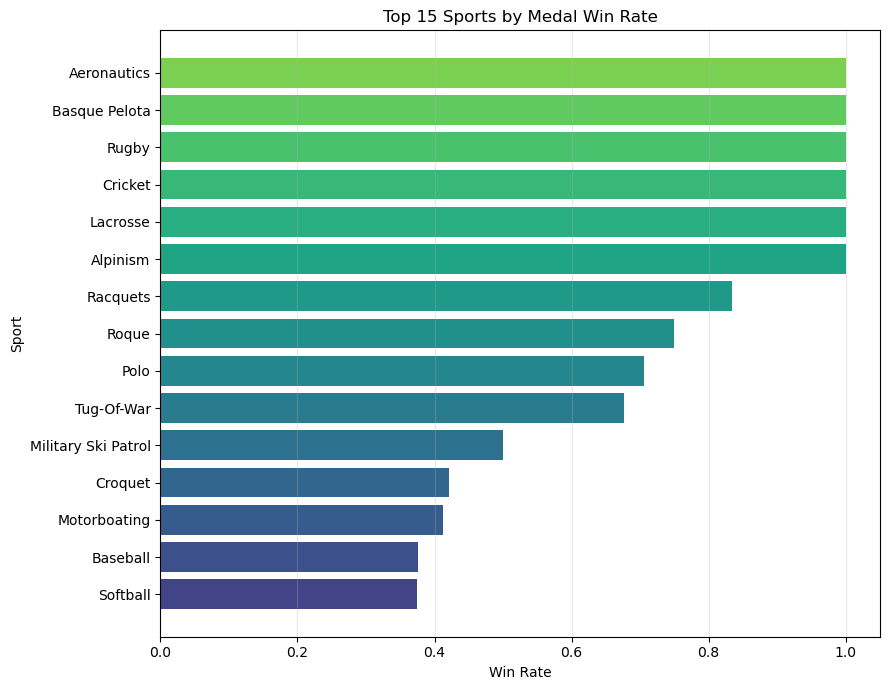

In [25]:
sport_win_rate = df_olympic.groupby('Sport')['Won_Medal'].mean().sort_values(ascending=False)

top_15 = sport_win_rate.head(15)

plt.figure(figsize=(9,7))
plt.barh(top_15.index, top_15.values, color=plt.cm.viridis_r(np.linspace(0.2,0.8,len(top_15))))
plt.title('Top 15 Sports by Medal Win Rate')
plt.xlabel('Win Rate')
plt.ylabel('Sport')
plt.gca().invert_yaxis()  # highest at top
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### Caution: Interpreting Win Rate by Sport
The chart above shows several sports (e.g., **Aeronautics, Basque Pelota, Rugby, Cricket, Lacrosse**) at a **100% win rate**. This is not a genuine pattern — it reflects tiny historical one-off events with very few total participants, where nearly everyone recorded happened to medal (e.g., a single small team event held once). Win rate by sport should always be interpreted alongside participant count, not viewed in isolation, since sports with many recurring individual events (like Athletics or Swimming) have a much larger and more reliable sample than one-off historical sports.


## Interim Recap
The analysis so far has covered win rates, country rankings, participation trends, and physical profile trends using the full combined dataset. The next sections dig deeper — splitting by season and identifying standout individual athletes — before a full summary at the end.


## Splitting Data by Season
Since Summer and Winter Olympics differ substantially in sports, historical scale, and participating nations, the dataset is split into two separate dataframes — `df_summer` and `df_winter` — to allow each season to be analyzed on its own terms, rather than blending fundamentally different competitions into a single set of numbers. This also lets us test whether patterns found in the combined dataset (like the small gender win-rate gap) hold up consistently within each season individually.


In [26]:
df_summer = df_olympic[df_olympic['Season'] == 'Summer'].copy()
df_winter = df_olympic[df_olympic['Season'] == 'Winter'].copy()

print("Summer records:", df_summer.shape[0])
print("Winter records:", df_winter.shape[0])

Summer records: 222552
Winter records: 48564


## Medal Win Rate by Gender, Split by Season
Testing whether the small overall gender gap (15.1% women vs. 14.5% men) holds consistently across both seasons, or whether it's driven by one season in particular.


In [28]:
df_summer.groupby('Sex')['Won_Medal'].mean()

Sex
F    0.158841
M    0.151101
Name: Won_Medal, dtype: float64

In [29]:
df_winter.groupby('Sex')['Won_Medal'].mean()

Sex
F    0.120101
M    0.115992
Name: Won_Medal, dtype: float64

**Insight:** the gender gap holds in **both** seasons, and is actually **wider in Winter** (12.0% women vs. 11.6% men) than in **Summer** (15.9% women vs. 15.1% men) — though Summer win rates are higher overall for both genders. This confirms the gender pattern isn't an artifact of one season dominating the combined numbers — it's a consistent, if modest, pattern across both.


## Top 5 Countries by Medals, Split by Season


In [31]:
df_olympic.columns

Index(['ID', 'Name', 'Sex', 'Age', 'Height', 'Weight', 'Team', 'NOC', 'Games',
       'Year', 'Season', 'City', 'Sport', 'Event', 'Medal', 'Won_Medal',
       'Age_Group', 'Decade', 'BMI'],
      dtype='object')

In [32]:
df_summer[df_summer['Won_Medal'] == 1].groupby('NOC')['Medal'].count().sort_values(ascending=False).head(5)

NOC
USA    5002
URS    2063
GBR    1985
GER    1779
FRA    1627
Name: Medal, dtype: int64

In [33]:
df_winter[df_winter['Won_Medal'] == 1].groupby('NOC')['Medal'].count().sort_values(ascending=False).head(5)

NOC
USA    635
CAN    611
NOR    443
URS    440
SWE    428
Name: Medal, dtype: int64

### Insight: Top 5 Countries — Summer vs. Winter (by NOC)

**Summer Olympics — Top 5:**
1. **USA** (United States) — 5,002 medals
2. **URS** (Soviet Union) — 2,063 medals
3. **GBR** (Great Britain) — 1,985 medals
4. **GER** (Germany) — 1,779 medals
5. **FRA** (France) — 1,627 medals

**Winter Olympics — Top 5:**
1. **USA** (United States) — 635 medals
2. **CAN** (Canada) — 611 medals
3. **NOR** (Norway) — 443 medals
4. **URS** (Soviet Union) — 440 medals
5. **SWE** (Sweden) — 428 medals

**Summary:**
The **USA leads both Summer and Winter Olympics**, making it the only country to top both seasons. Beyond that, 
the two rankings diverge sharply — only the USA and URS appear in both top-5 lists. **Canada, Norway, and 
Sweden** are strong Winter-specific performers that don't crack Summer's top 5 at all, reflecting their 
traditional strength in winter sports like ice hockey and skiing. Conversely, **Great Britain, Germany, and 
France** — all Summer powerhouses — are absent from the Winter top 5 entirely, since their historical medal 
strength lies in Summer-specific sports (athletics, cycling, rowing, etc.) rather than winter disciplines.

This divergence makes sense given the fundamentally different sport profiles of each season: Winter Olympics 
require climate/infrastructure suited to snow and ice sports, naturally favoring a smaller, more specialized 
set of nations compared to Summer's much broader range of sports and larger pool of competing countries.

## Top 5 Athletes by Total Medals


In [61]:
top_athletes = (df_olympic[df_olympic['Won_Medal'] == 1]
                 .groupby('Name')['Medal']
                 .count()
                 .sort_values(ascending=False)
                 .head(5))

top_athletes

Name
Michael Fred Phelps, II               28
Larysa Semenivna Latynina (Diriy-)    18
Nikolay Yefimovich Andrianov          15
Borys Anfiyanovych Shakhlin           13
Takashi Ono                           13
Name: Medal, dtype: int64

**Insight:** **Michael Phelps leads by a massive margin with 28 total medals**, nearly 10 medals ahead of the next closest athlete (Larysa Latynina, 18). The next four — Latynina (18), Nikolay Andrianov (15), Borys Shakhlin (13), and Takashi Ono (13) — are all gymnasts, highlighting how gymnastics' multiple individual apparatus events (as opposed to sports with a single event per competitor) makes it structurally possible to accumulate many medals across a single Games.


## Medal Breakdown by Type (Gold / Silver / Bronze) per Athlete
Total medal count alone doesn't distinguish an athlete who wins gold every time from one who reaches the podium often but rarely finishes first — breaking it down by medal type gives a fuller picture.


In [44]:
top_athletes_breakdown = (df_olympic[df_olympic['Won_Medal'] == 1]
                           .groupby(['Name', 'Medal'])
                           .size()
                           .unstack(fill_value=0))

top_athletes_breakdown['Total'] = top_athletes_breakdown.sum(axis=1)
top_athletes_breakdown.sort_values('Total', ascending=False).head(10)

Medal,Bronze,Gold,Silver,Total
Name,,,,
"Michael Fred Phelps, II",2,23,3,28
Larysa Semenivna Latynina (Diriy-),4,9,5,18
Nikolay Yefimovich Andrianov,3,7,5,15
Borys Anfiyanovych Shakhlin,2,7,4,13
Takashi Ono,4,5,4,13
Ole Einar Bjrndalen,1,8,4,13
Edoardo Mangiarotti,2,6,5,13
Ryan Steven Lochte,3,6,3,12
Birgit Fischer-Schmidt,0,8,4,12


**Insight:** Phelps' total is overwhelmingly gold-heavy (23 gold / 3 silver / 2 bronze out of 28), reinforcing that his dominance wasn't just about reaching the podium repeatedly — he won outright the vast majority of the time. Latynina's breakdown (9 gold / 5 silver / 4 bronze) is more evenly spread, suggesting elite but not always first-place-level consistency across her career.


## Top Medalists by Medal Type


In [69]:
top_gold = (df_olympic[df_olympic['Medal'] == 'Gold']
            .groupby('Name')['Medal']
            .count()
            .sort_values(ascending=False)
            .head(5))

# Top Silver medal winners
top_silver = (df_olympic[df_olympic['Medal'] == 'Silver']
              .groupby('Name')['Medal']
              .count()
              .sort_values(ascending=False)
              .head(5))

# Top Bronze medal winners
top_bronze = (df_olympic[df_olympic['Medal'] == 'Bronze']
              .groupby('Name')['Medal']
              .count()
              .sort_values(ascending=False)
              .head(5))

print("Top 5 Gold Medal Winners:\n", top_gold, "\n")
print("Top 5 Silver Medal Winners:\n", top_silver, "\n")
print("Top 5 Bronze Medal Winners:\n", top_bronze)

Top 5 Gold Medal Winners:
 Name
Michael Fred Phelps, II               23
Raymond Clarence "Ray" Ewry           10
Paavo Johannes Nurmi                   9
Larysa Semenivna Latynina (Diriy-)     9
Mark Andrew Spitz                      9
Name: Medal, dtype: int64 

Top 5 Silver Medal Winners:
 Name
Mikhail Yakovlevich Voronin        6
Shirley Frances Babashoff          6
Aleksandr Nikolayevich Dityatin    6
Aleksandr Vladimirovich Popov      6
Yang Yang                          6
Name: Medal, dtype: int64 

Top 5 Bronze Medal Winners:
 Name
Aleksey Yuryevich Nemov     6
Harri Tapani Kirvesniemi    6
Heikki Ilmari Savolainen    6
Franziska van Almsick       6
Merlene Joyce Ottey-Page    6
Name: Medal, dtype: int64


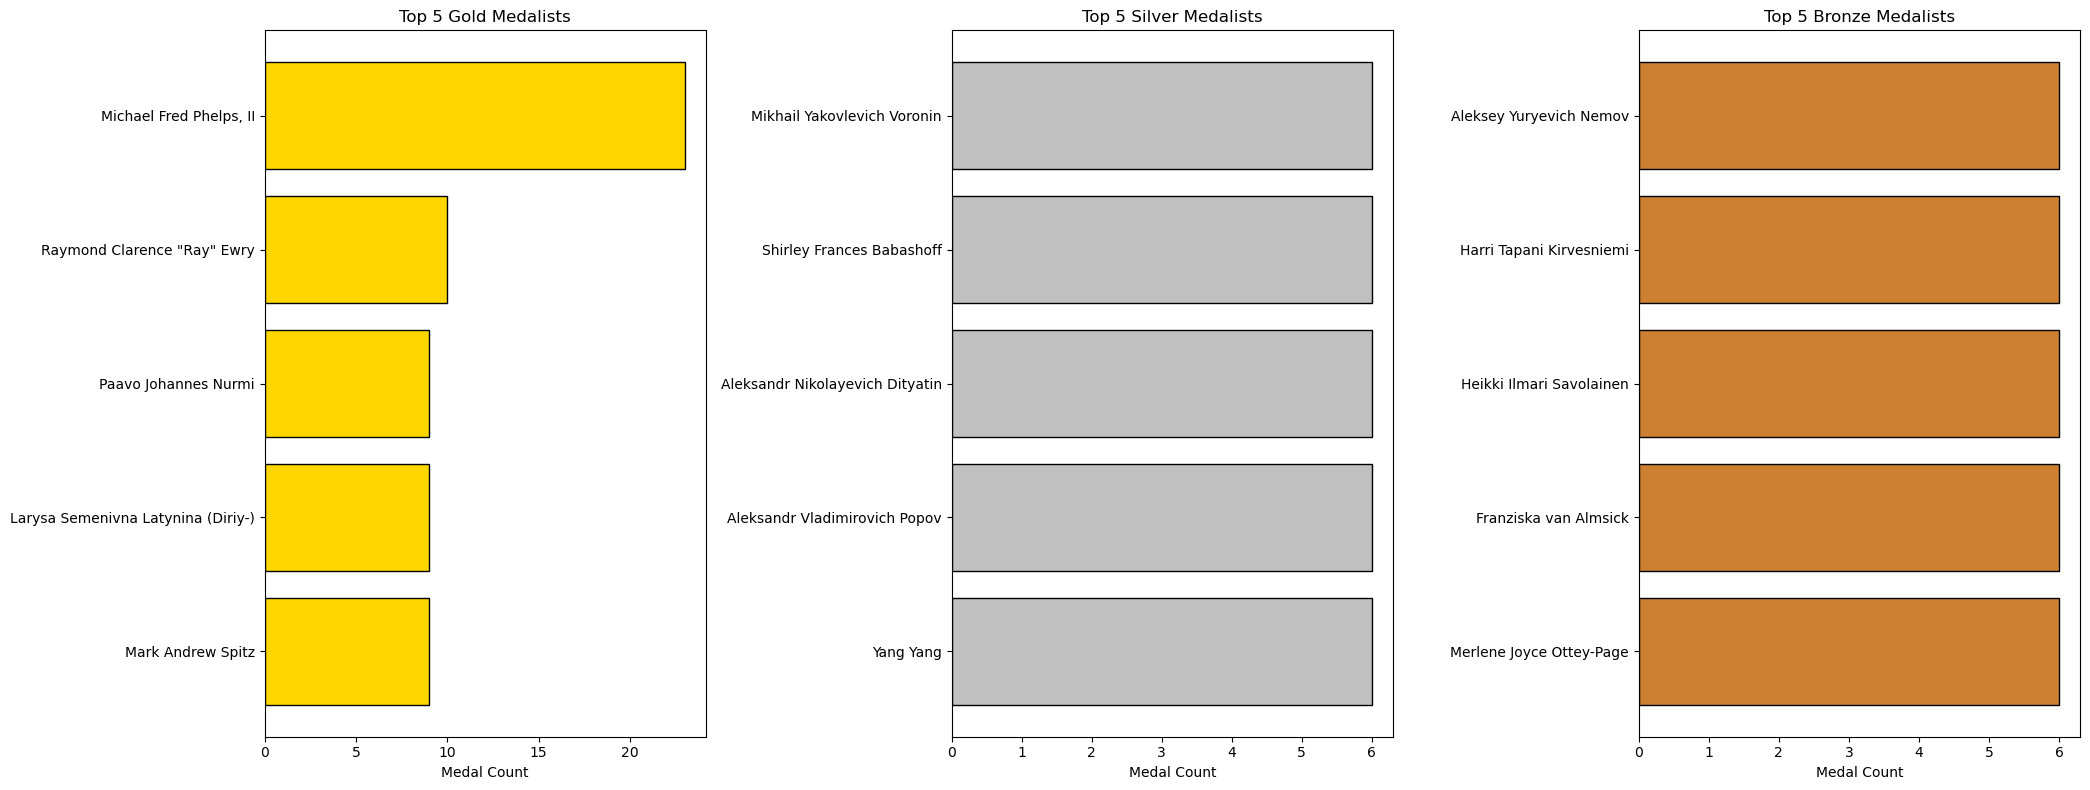

In [74]:
fig, axes = plt.subplots(1, 3, figsize=(21, 8))
colors = ['#FFD700', '#C0C0C0', '#CD7F32']  # FFD700=gold, C0C0C0=silver, CD7F32=bronze
data = [top_gold, top_silver, top_bronze]
titles = ['Top 5 Gold Medalists', 'Top 5 Silver Medalists', 'Top 5 Bronze Medalists']

for medal, d, title, color in zip(axes, data, titles, colors):
    medal.barh(d.index[::-1], d.values[::-1], color=color, edgecolor='black')
    medal.set_title(title)
    medal.set_xlabel('Medal Count')

plt.tight_layout()
plt.show()

### Insight: Top Medalists by Medal Type

**Top Gold Medalists:**
1. **Michael Fred Phelps, II** — 23 gold medals
2. Raymond Clarence "Ray" Ewry — 10
3. Paavo Johannes Nurmi — 9
4. Larysa Semenivna Latynina (Diriy-) — 9
5. Mark Andrew Spitz — 9

**Top Silver Medalists:** a 5-way tie at 6 silver medals each — Mikhail Yakovlevich Voronin, Shirley Frances 
Babashoff, Aleksandr Nikolayevich Dityatin, Aleksandr Vladimirovich Popov, and Yang Yang.

**Top Bronze Medalists:** also a 5-way tie at 6 bronze medals each — Aleksey Yuryevich Nemov, Harri Tapani 
Kirvesniemi, Heikki Ilmari Savolainen, Franziska van Almsick, and Merlene Joyce Ottey-Page.

**Key takeaway:** Michael Phelps stands alone at the top of the Gold rankings by a wide margin — 23 golds is 
more than double the next closest athlete (10). This is consistent with his real-world status as the most 
decorated Olympian in history. Interestingly, the Silver and Bronze categories look completely different: 
rather than one dominant athlete, both are crowded five-way ties at 6 medals each, suggesting that reaching 
the podium repeatedly *without* winning gold is a much more evenly distributed achievement across many great 
athletes, whereas dominating at the very top (gold) is far rarer and concentrated in a handful of standout names.

## Project Summary

### What This Project Analyzed
This project explored **120 years of Olympic history (1896–2016)** using a dataset of 271,116 individual athlete-event records, covering both Summer and Winter Games. The analysis looked at medal success across gender, age, and physical profile (BMI); country-level performance overall and split by season; participation trends over time; and standout individual athletes.

### Project Workflow
1. **Data Loading & Inspection** — loaded `athlete_events.csv`, checked shape, dtypes, and missing values.
2. **Data Cleaning** — handled `Medal` nulls (filled with `'No Medal'`, since missing here reflects a real outcome, not bad data) rather than dropping the column or the rows.
3. **Feature Engineering** — used NumPy to derive new columns: `Won_Medal` (`np.where`), `Age_Group` (`np.select`), `Decade`, and `BMI`.
4. **Univariate & Grouped KPIs** — calculated win rates by gender, age group, country, and sport, with appropriate caution applied where small sample sizes could distort results (e.g., raw per-age win rate, and sports with 100% win rates from one-off historical events).
5. **Time-Based Analysis** — examined participation growth, gender participation trends, and physical profile (Age/Height/Weight) trends across 12 decades.
6. **Segmented Analysis** — split the dataset into `df_summer` and `df_winter` to compare gender win rates and top countries within each season individually, rather than only looking at combined totals.
7. **Athlete-Level Analysis** — identified the most decorated individual athletes overall and by medal type (Gold/Silver/Bronze), including a breakdown of medal composition per athlete.

### Key Findings
- **Overall medal win rate: 14.67%**, with a small, consistent gender gap (women 15.1% vs. men 14.5%) that holds in both Summer and Winter when analyzed separately — actually slightly wider in Winter.
- **Peak performance skews toward the 30-39 age bracket (16.1% win rate)**, ahead of the more commonly assumed peak-20s range — challenging the intuitive assumption that younger athletes perform best.
- **BMI shows only a weak relationship with medal success** (23.16 for medalists vs. 22.72 for non-medalists), unsurprising given how physically different Olympic sports are from one another.
- **The USA leads in total medals overall and in both Summer and Winter individually** — the only country to top both seasons. Winter's next-best countries (Canada, Norway, Sweden) are almost entirely different from Summer's (Soviet Union, Great Britain, Germany, France), reflecting each season's distinct sport profile.
- **Age, Height, and Weight all follow a U-shaped trend across the 12 decades** — rising in the Games' early era, dipping through the mid-20th century as the Olympics rapidly expanded to more countries and sports, then rising again modestly in the modern era.
- **Women's participation grew from near-zero in the earliest Games to a substantial share by recent Games** — the single most dramatic trend found in the entire dataset.
- **Michael Phelps is the most decorated athlete by a wide margin (28 total medals, 23 of them gold)** — his dominance is overwhelmingly gold-heavy, unlike other top athletes (mostly gymnasts) whose medal counts are more evenly spread across Gold/Silver/Bronze.
- **Win rate by sport requires caution** — several sports show misleadingly perfect win rates due to tiny historical sample sizes, a reminder to always check participant counts before trusting a rate-based metric.

### Techniques Demonstrated
- Deliberate handling of "meaningful missingness" (`Medal`) vs. genuine missing data (`Age`/`Height`/`Weight`)
- NumPy-based feature engineering: `np.where()` and `np.select()` for binary flags and multi-condition bucketing
- Grouped and pivoted aggregation across multiple dimensions (gender, age, country, season, decade, sport)
- Consistent use of sample-size caution when interpreting rate-based metrics
- Comparative/segmented analysis (Summer vs. Winter) rather than relying solely on combined totals
